class          
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
Tasa de aciertos: 0.6


Text(0, 0.5, 'sepal_width')

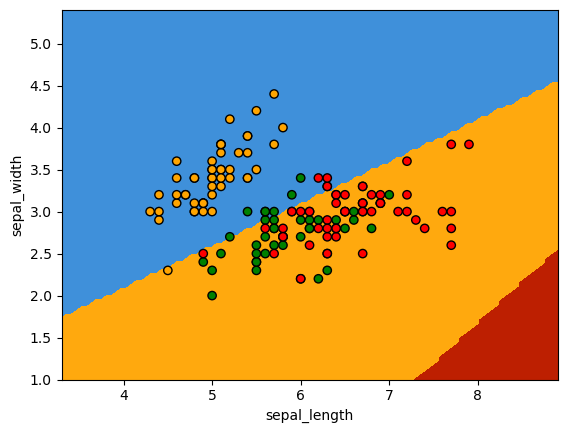

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score
from sklearn.inspection import DecisionBoundaryDisplay

#!wget https://archive.ics.uci.edu/static/public/53/iris.zip
#!unzip iris.zip
df = pd.read_csv("iris.data", names=['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class'])

print(df[["class"]].value_counts())
# Dos clases (clasificación binaria)
#df = df[df['class'].isin(['Iris-setosa', 'Iris-versicolor'])]
# x, y
x = df[['sepal_length', 'sepal_width']]
y = df['class']
# Creación de un clasificador lineal (perceptron)
clf = Perceptron()
# Entrenamiento del clasificador
clf.fit(x, y)
# Predicción para datos de entrenamiento
y_pred = clf.predict(x)
# Tasa de aciertos
acc_score = accuracy_score(y, y_pred)
print('Tasa de aciertos: {acc_sc}'.format(acc_sc=acc_score))
# Mostrar fronteras de decisión del clasificador
DecisionBoundaryDisplay.from_estimator(clf, x, response_method="predict")
# Mostrar datos de entrenamiento
colores = {'Iris-setosa':'orange', 'Iris-versicolor':'green', 'Iris-virginica': 'red' }
plt.scatter(x['sepal_length'], x['sepal_width'], c=y.map(colores), edgecolor='k')
plt.xlabel("sepal_length")
plt.ylabel("sepal_width")

In [4]:
clf.coef_, clf.intercept_, clf.feature_names_in_

(array([[-25.6,  43.5],
        [ 10.2, -28. ],
        [ 17.2, -35.2]]),
 array([ 10.,  16., -28.]),
 array(['sepal_length', 'sepal_width'], dtype=object))

Prediccions (valors de la funció de decisió):
[[-24.36  -0.18 -21.64]
 [ 29.38 -32.26 -63.72]
 [-74.02  21.74  12.92]
 [-17.45  -4.   -26.88]
 [-42.28   6.96  -9.6 ]
 [ 19.66 -24.12 -54.8 ]
 [ -7.21  -8.08 -33.76]
 [-31.79  -0.42 -18.44]
 [-53.02  17.64   1.2 ]
 [-21.03  -0.44 -23.28]]


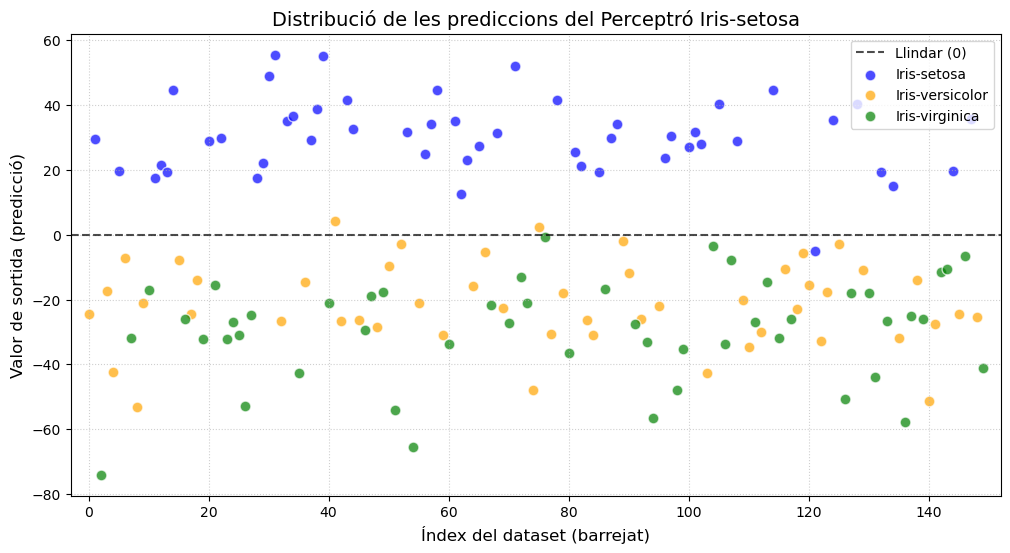

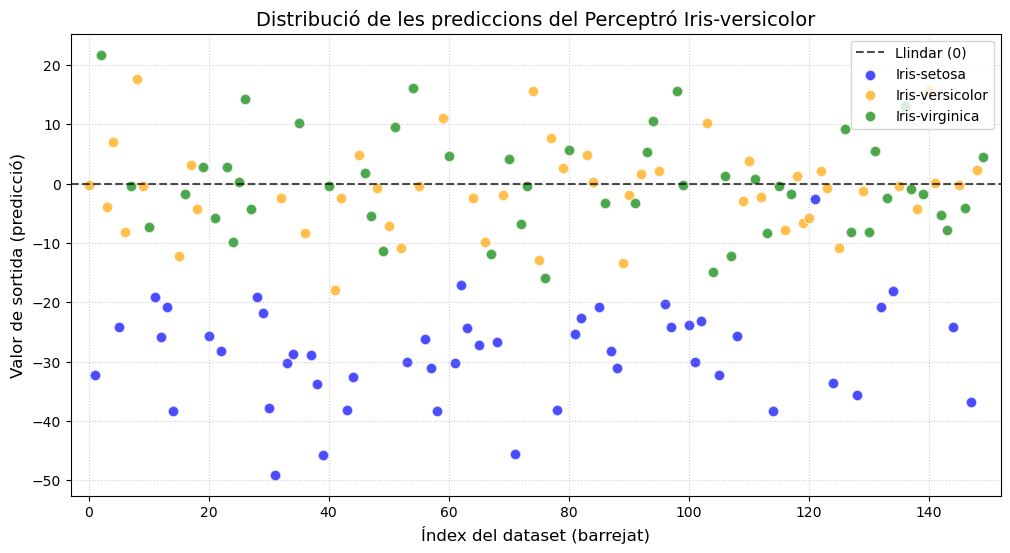

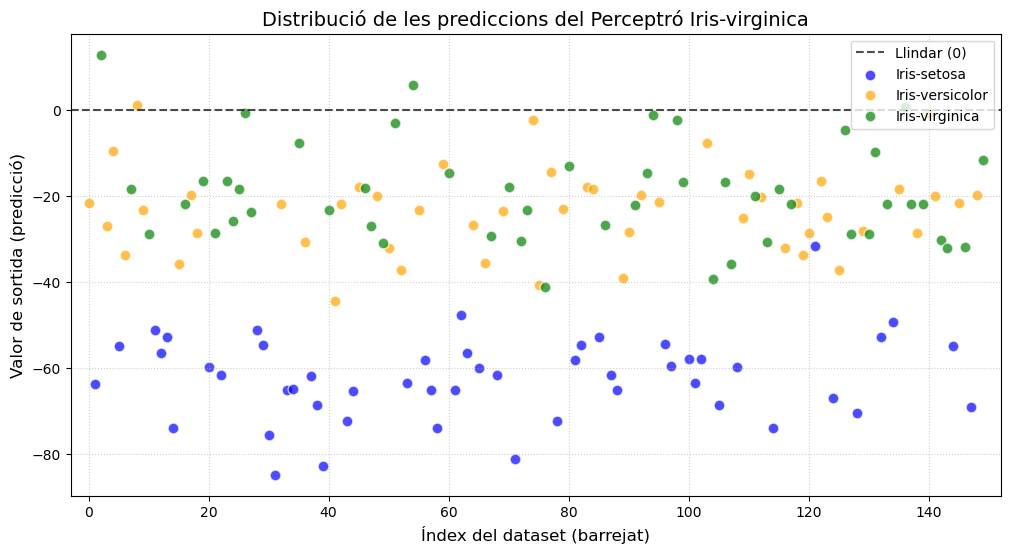

In [19]:
# Ordenem el DataFrame de manera aleatòria per a la visualització
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)

x = df_shuffled[['sepal_length', 'sepal_width']]
y = df_shuffled['class']

# .predict retorna la classe predicha, mentre que .decision_function retorna el valor de la funció de decisió (la distància a la frontera de decisió).
y_pred = clf.decision_function(x)
print("Prediccions (valors de la funció de decisió):")
print(y_pred[:10])  # Mostrem només les primeres 10 prediccions


colors = {
    'Iris-setosa': 'blue', 
    'Iris-versicolor': 'orange', 
    'Iris-virginica': 'green'
}

for i, class_name in enumerate(clf.classes_):
    plt.figure(figsize=(12, 6))

    # Línia de referència (llindar de decisió en 0)
    plt.axhline(0, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='Llindar (0)')

    # Dibuixem un scatter plot per a cada classe real per separat
    for target_class, color in colors.items():
        # Creem una màscara per filtrar només les files d'aquesta classe
        mask = df_shuffled['class'] == target_class
        
        plt.scatter(
            df_shuffled.index[mask], 
            y_pred[mask, i],  # Apliquem la mateixa màscara a les prediccions
            s=60, 
            alpha=0.7, 
            edgecolors='w',
            c=color,
            label=target_class  # Ara sí que agafarà el nom de la classe per a la llegenda
        )

    # Millores visuals
    plt.title(f'Distribució de les prediccions del Perceptró {class_name}', fontsize=14)
    plt.xlabel('Índex del dataset (barrejat)', fontsize=12)
    plt.ylabel('Valor de sortida (predicció)', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.6)
    
    # La llegenda ara mostrarà el Llindar (0) i les 3 flors amb els seus colors
    plt.legend(loc='upper right')

    # Afegim una mica d'espai als marges
    plt.margins(x=0.02)

    plt.show()





> Amb la representació DecisionBoundaryDisplay interpreta la qualitat del model amb aquestes variables.

> Imprimeix els paràmetres del model perceptron entrenat de l'anterior exercici. Interpreta el significat dels paràmetres amb les teues paraules.

> Interpreta perquè creus que no ha funcionat bé amb dues de les classes observant el gràfic de separabilitat i el DecisionBoundaryDisplay. Perquè al gràfic de separabilitat apareixen algunes com a Virginica i a l'altre cap?